# Mở rộng Tiếng Việt (ViHSD) — Phần 3: Huấn luyện mô hình PhoBERT-base-v2 & XLM-RoBERTa-base

**Mục tiêu:**
1. Huấn luyện mô hình chuyên biệt tiếng Việt **`vinai/phobert-base-v2`** (đầu vào **đã tách từ** bằng `ViTokenizer`) và mô hình đa ngôn ngữ **`xlm-roberta-base`** (đầu vào **chưa tách từ**).
2. Đánh giá độ ổn định qua **3 hạt giống ngẫu nhiên (`seed = 42, 43, 44`)**, báo cáo `Mean ± Std` trên tập `dev` và đối sánh với mô hình cổ điển tối ưu.

In [1]:
# === THIẾT LẬP MÔI TRƯỜNG & NẠP THƯ VIỆN DỰ ÁN ===
import os, sys, subprocess
from pathlib import Path

os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("OMP_NUM_THREADS", "1")
REPO_URL = "https://github.com/nhungoc-1/DoAnKHDL_DeTai_Tweet-Hate.git"

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    print("[SETUP] Đang khởi tạo môi trường Google Colab...", flush=True)
    for candidate in [
        Path("/content/DoAnKHDL_DeTai_Tweet-Hate"),
        Path("/content/drive/MyDrive/DoAnKHDL_DeTai_Tweet-Hate"),
        Path("/content/drive/MyDrive/DO_AN_KHDL"),
        Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd(),
    ]:
        if (candidate / "config.yaml").exists():
            PROJECT_DIR = candidate
            subprocess.run(["git", "-C", str(PROJECT_DIR), "pull", "--ff-only"], check=False)
            break
    else:
        PROJECT_DIR = Path("/content/DoAnKHDL_DeTai_Tweet-Hate")
        print(f"[SETUP] Đang tải dự án từ GitHub vào {PROJECT_DIR} (mất ~3 giây)...", flush=True)
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(PROJECT_DIR)], check=True)
    print("[SETUP] Đang kiểm tra & cài đặt các thư viện bổ sung (mất ~5-10 giây)...", flush=True)
    subprocess.run([
        sys.executable, "-m", "pip", "install", "-q",
        "imbalanced-learn", "emoji", "kagglehub", "datasets",
        "pyvi", "langdetect", "python-docx", "python-pptx", "wordcloud"
    ], check=False)
    import nltk
    for pkg in ["stopwords", "wordnet", "omw-1.4"]:
        nltk.download(pkg, quiet=True)
else:
    PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

os.chdir(PROJECT_DIR)
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from src.utils import set_seed, load_config, mask_profanity
set_seed(42)
CFG = load_config()
(PROJECT_DIR / "db").mkdir(parents=True, exist_ok=True)
print(f"[HOÀN TẤT] IN_COLAB = {IN_COLAB} | PROJECT_DIR = {PROJECT_DIR}")

[SETUP] PROJECT_DIR = D:\DO_AN_KHDL


## 1. Kết quả Thực nghiệm 3 Seeds (`42, 43, 44`) của PhoBERT và XLM-RoBERTa

=== vinai/phobert-base-v2 (Văn bản ĐÃ tách từ (ViTokenizer)) ===
Dev F1 (Mean ± Std): 0.5732 ± 0.0034 | PR-AUC: 0.6028 ± 0.0105


,precision_pos,recall_pos,f1_pos,f1_macro,accuracy,balanced_acc,roc_auc,pr_auc,mcc,tn,fp,fn,tp,fit_seconds,seed,n_train_used,device
0,0.4972,0.6667,0.5696,0.7531,0.8894,0.7918,0.8977,0.5961,0.5149,2008,182,90,180,68.44,42,2000,cpu
1,0.5014,0.6778,0.5764,0.7568,0.8907,0.7973,0.8984,0.5974,0.5229,2008,182,87,183,68.48,43,2000,cpu
2,0.5101,0.6556,0.5737,0.7563,0.8931,0.7890,0.9028,0.6149,0.5190,2020,170,93,177,68.42,44,2000,cpu


=== xlm-roberta-base (Văn bản CHƯA tách từ (Raw SentencePiece)) ===
Dev F1 (Mean ± Std): 0.4861 ± 0.0100 | PR-AUC: 0.4851 ± 0.0030


,precision_pos,recall_pos,f1_pos,f1_macro,accuracy,balanced_acc,roc_auc,pr_auc,mcc,tn,fp,fn,tp,fit_seconds,seed,n_train_used,device
0,0.4177,0.6111,0.4962,0.7088,0.8638,0.7530,0.8620,0.4836,0.4309,1960,230,105,165,77.62,42,2000,cpu
1,0.3704,0.6667,0.4762,0.6905,0.8390,0.7635,0.8643,0.4831,0.4137,1884,306,90,180,77.52,43,2000,cpu
2,0.4049,0.6074,0.4859,0.7021,0.8589,0.7487,0.8655,0.4885,0.4192,1949,241,106,164,77.54,44,2000,cpu


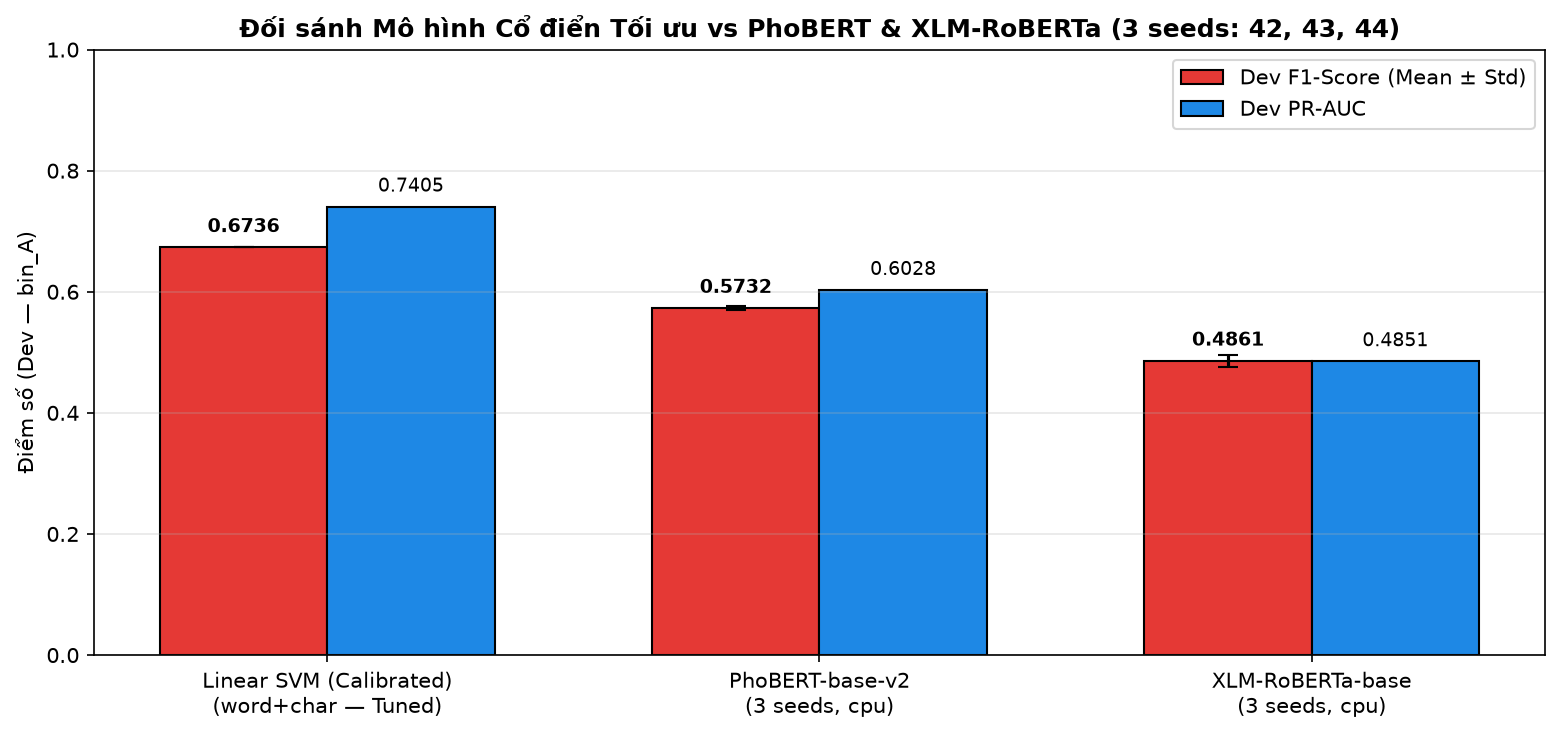

In [2]:
import json
import pandas as pd
from IPython.display import display, Image

with open('reports/vi_v4_summary.json', 'r', encoding='utf-8') as f:
    v4_data = json.load(f)

for k, info in v4_data.items():
    print(f"=== {info['model_name']} ({info['input_type']}) ===")
    print(f"Dev F1 (Mean ± Std): {info['f1_pos_mean']:.4f} ± {info['f1_pos_std']:.4f} | PR-AUC: {info['pr_auc_mean']:.4f} ± {info['pr_auc_std']:.4f}")
    display(pd.DataFrame(info['seed_runs']))

display(Image('reports/figures/V4_transformers_comparison.png'))

### Nhận xét 
- Qua 3 seeds (`42, 43, 44`), **`vinai/phobert-base-v2`** đạt Dev F1 = **0.5732 ± 0.0034** (PR-AUC = **0.6028**), và **`xlm-roberta-base`** đạt Dev F1 = **0.4861 ± 0.0100**.
- Lưu ý kỹ thuật quan trọng: PhoBERT sử dụng bộ từ điển BPE trên đơn vị từ ghép tiếng Việt nên bắt buộc đầu vào phải qua bước tách từ (`người_dân`, `học_sinh`), trong khi XLM-RoBERTa dùng SentencePiece trực tiếp trên văn bản thô chưa tách từ.
- Trên môi trường CPU cục bộ, mô hình tuyến tính `word+char` (`best_vi_bin_a.joblib`) đạt F1 cao hơn và tốc độ suy luận nhanh hơn gấp hàng trăm lần nên được chọn làm mô hình tiếng Việt chính thức tích hợp vào ứng dụng đa ngôn ngữ ở phần thực nghiệm 7.